# Single-file puncta and synapse analysis

This notebook analyzes a 3D, four-channel microscopy image. It corrects Z-drift, detects puncta, identifies candidate synapses from PSD and RIM clusters, and measures associations with A1 and PRRT puncta.

## Input and channels

The image is loaded from a CZI file using `BioImage`. Channel coordinates are assigned in this order:

- **PRRT**
- **A1**
- **PSD**
- **RIM**

Spatial coordinates are in micrometers.

## Workflow

1. **Load the image**  
    Load the CZI file and assign channel names.

2. **Correct Z-drift**  
    Estimate shifts between sequential Z-planes and create a stabilized image. Plot the estimated shifts and correction result.

3. **Detect puncta**  
    Detect puncta in the selected image region using channel-specific detection settings. Plot the image and detected points.

4. **Cluster PSD and RIM puncta**  
    Apply DBSCAN to PSD and RIM points to identify candidate clusters. Points that are not assigned to a cluster are treated as noise.

5. **Associate PSD and RIM clusters**  
    Pair nearby PSD and RIM clusters to identify candidate synapses. Review the paired clusters and their distances.

6. **Pair A1 and PRRT puncta**  
    Associate nearby A1 and PRRT puncta and assign pair IDs.

7. **Profile synapses**  
    Associate puncta with synapses and calculate distances to puncta in the other channels.

8. **Summarize and visualize results**  
    Calculate global and per-synapse statistics, then plot the summary figures and distance distributions.

## Parameters and run-specific settings

The `parameters` dictionary defines channel names, detection settings, DBSCAN settings, synapse distance, and A1–PRRT pairing distance. Some calls in this notebook pass values directly and therefore override the dictionary settings. In particular, clustering uses `eps=1.5`, and `pair_puncta` uses `distance=10`.

Detection and plotting use a cropped region of the stabilized image: `Y=250:500` and `X=800:1000` in array indices. Interpret the resulting measurements as applying to this analyzed region.

In [1]:
%load_ext autoreload
%autoreload 2

In [18]:
from pathlib import Path

import napari
from bioio import BioImage

import synxm

parameters = {
    "channels": ["PRRT", "A1", "PSD", "RIM"],
    "detection": {
        "PRRT": {"scale_um": 0.4, "specificity": 6},
        "A1": {"scale_um": 0.3, "specificity": 8},
        "PSD": {"scale_um": 0.1, "specificity": 8},
        "RIM": {"scale_um": 0.1, "specificity": 8},
    },
    "dbscan": {"channels": ["RIM", "PSD"],"eps": 1.5, "min_samples": 3},
    "synapse": {"distance": 1.0, "channels": ["RIM", "PSD"]},
    "pairs": {"distance": 0.5, "channels": ["A1", "PRRT"]},
    "association": {"distance": 1.0, "channels": ["A1", "PRRT"]}
}

# data_path = Path("/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261007 Repeat/Experiment-152.czi")
# data_path = Path("/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261006 Re-image/Re-image 261006 Experiment-134.czi")
data_path = Path("/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261020 Repeat/Experiment-358.czi")
# data_path = Path("/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261006 Re-image/Re-image 261006 Experiment-129.czi")
image = BioImage(data_path)
data = image.xarray_dask_data.assign_coords({"C": parameters["channels"]})
# data = image.xarray_data.assign_coords({"C": parameters["channels"]})
# data = data[:,:,:,250:500, 800:1000]


In [3]:
# v = napari.Viewer(ndisplay=3)
# v.add_image(data, channel_axis=1, name=parameters["channels"])

# 2. Drift correction

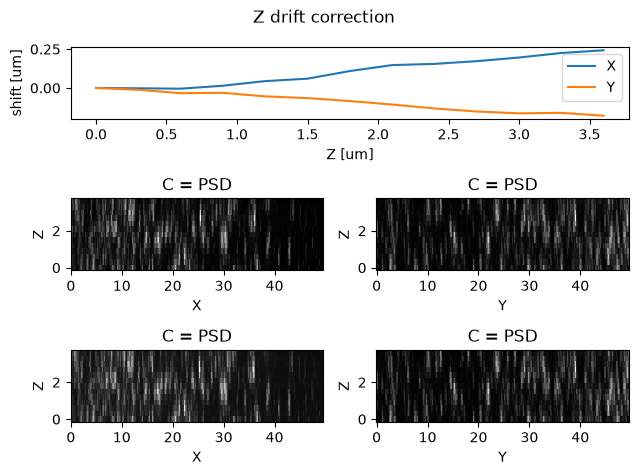

In [4]:
shifts, stabilized = synxm.correct_z_drift(data)
synxm.plot_drift_correction(data,stabilized,shifts)

In [5]:
# v.add_image(stabilized.data[0], channel_axis=1)

## 3. Spot detection

- Detect spots in all channels

(<Figure size 2000x2000 with 4 Axes>,
 {'A1': <Axes: title={'center': 'A1'}>,
  'PRRT': <Axes: title={'center': 'PRRT'}>,
  'PSD': <Axes: title={'center': 'PSD'}>,
  'RIM': <Axes: title={'center': 'RIM'}>})

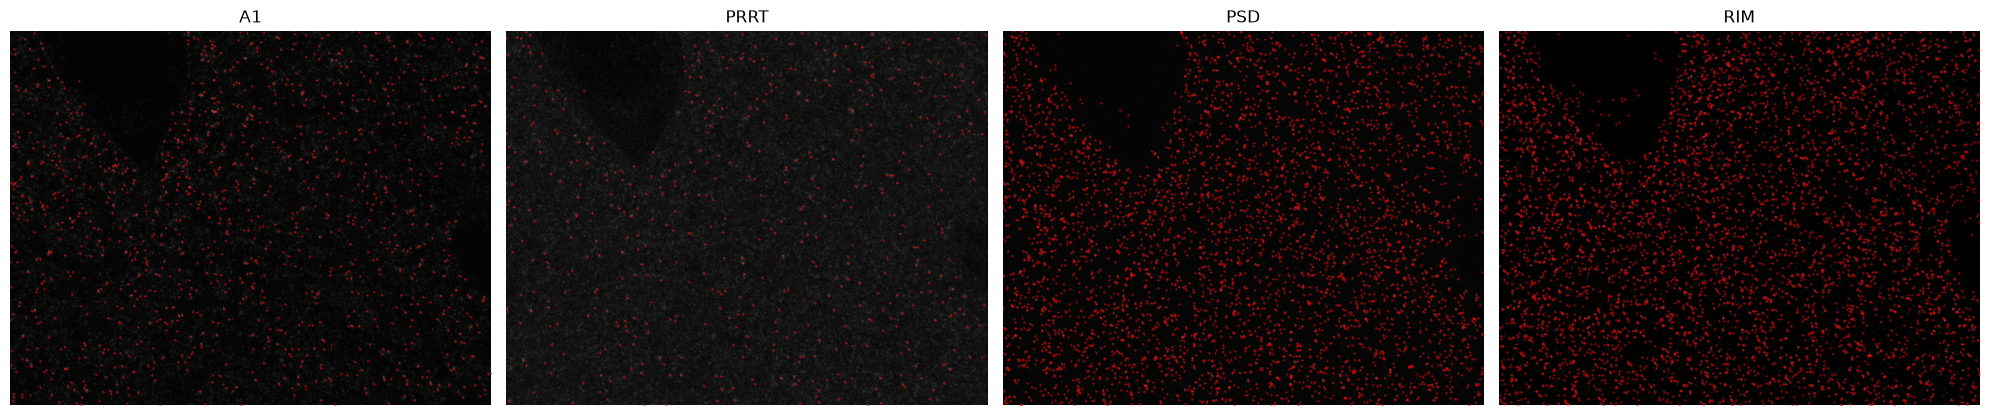

In [19]:
import matplotlib.pyplot as plt
import numpy as np

tmp = stabilized[0]#, :, :, 250:500, 800:1000]

points = synxm.detect_puncta(tmp, parameters["detection"])

fig = plt.figure(figsize=(20, 20))
fig, axes = synxm.plot_data(tmp, split=True, fig=fig)
synxm.plot_points(points, ms=1, split=True, axes_dict=axes)


In [7]:
# vx = np.array([(tmp[a][1].values - tmp[a][0].values) for a in ["Z", "Y", "X"]])
# o = np.array([tmp[a][0].values for a in ["Z", "Y", "X"]])
# fcol = {"PRRT": "magenta", "A1": "red", "PSD": "green", "RIM": "yellow"}
# for n, pts in points.groupby("C"):
#     v.add_image(tmp.sel(C=n), scale=vx, translate=o, name=n, colormap=fcol[n])
#     v.add_points(pts[["Z", "Y", "X"]], size=1, name=n, face_color=fcol[n])

## 3. Clustering of RIM and PSD channels
Cluster points to identify potential synapses.

,C,number of clusters,p-value
0,PSD,311,0.000999
1,RIM,459,0.000999


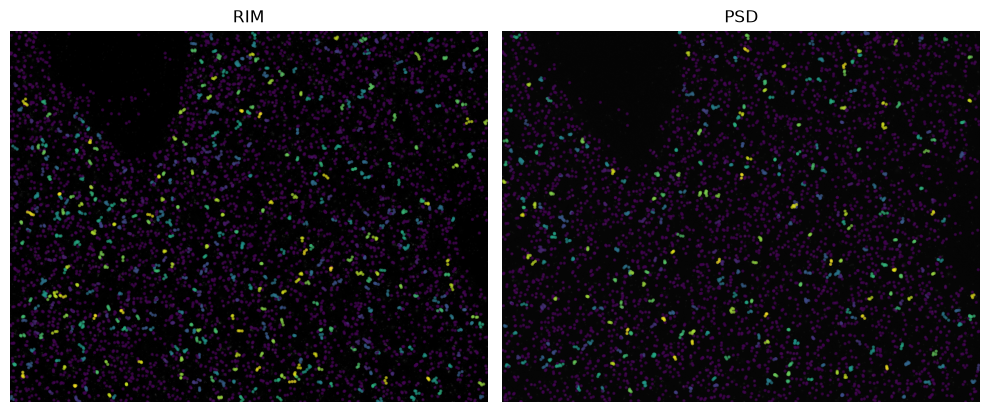

In [21]:

points, clusters = synxm.cluster_dbscan(points, **parameters["dbscan"])
pvalues_cluster = synxm.compute_dbscan_clustering_pvalue(points,**parameters["dbscan"])

fig = plt.figure(figsize=(10, 10))
fig, axes = synxm.plot_data(tmp.sel(C=["RIM", "PSD"]), split=True, fig=fig)
for n, g in points[points["C"].isin(["RIM", "PSD"])].groupby("C"):
    axes[n].scatter(g["X"], g["Y"], c=g["cluster_id"], s=2,alpha=0.5)
pvalues_cluster 

## 4. Pre-post synaptic cluster association
Identify synapses as pair of cluster

number of paired clusters :  112


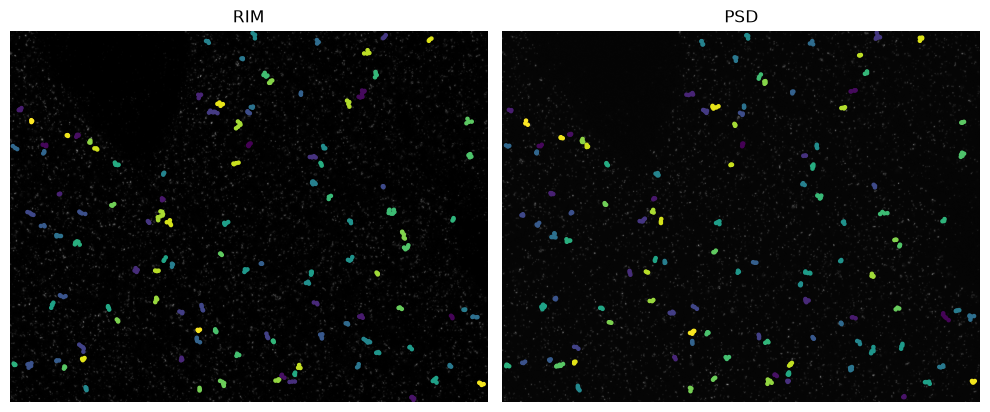

In [22]:

points, synapses = synxm.pair_cluster(points, **parameters["synapse"])

fig = plt.figure(figsize=(10, 10))
fig, axes = synxm.plot_data(tmp.sel(C=["RIM", "PSD"]), split=True, fig=fig)
for n, g in points[points["synapse_id"] >= 0].groupby("C"):
    axes[n].scatter(g["X"], g["Y"], c=g["synapse_id"], s=5)

print("number of paired clusters : ", len(synapses))

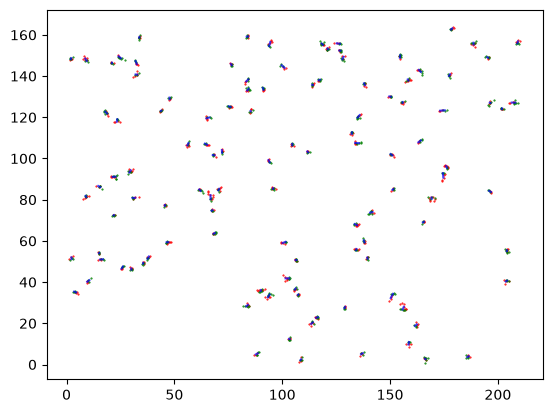

In [23]:

for n, g in points[points["synapse_id"] >= 0].groupby("synapse_id"):
    g1 = g[g["C"]=="RIM"]
    g2 = g[g["C"]=="PSD"]
    c1 = g1[["X","Y"]].mean(axis=0)
    c2 = g2[["X","Y"]].mean(axis=0)
    plt.plot(g1["X"], g1["Y"], 'ro',ms=0.5)
    plt.plot(g2["X"], g2["Y"], 'go',ms=0.5)
    plt.plot([c1["X"],c2["X"]],[c1["Y"],c2["Y"]],'b-',alpha=0.7)

## 5. Identify pair of A1-PRRT

Identify pair of A1-PRRT puncta


In [24]:
points, pairs = synxm.pair_puncta_many_to_many(points, **parameters["pairs"])

## 6. Synapse profiling

For each synapse, associate the puncate in all channel


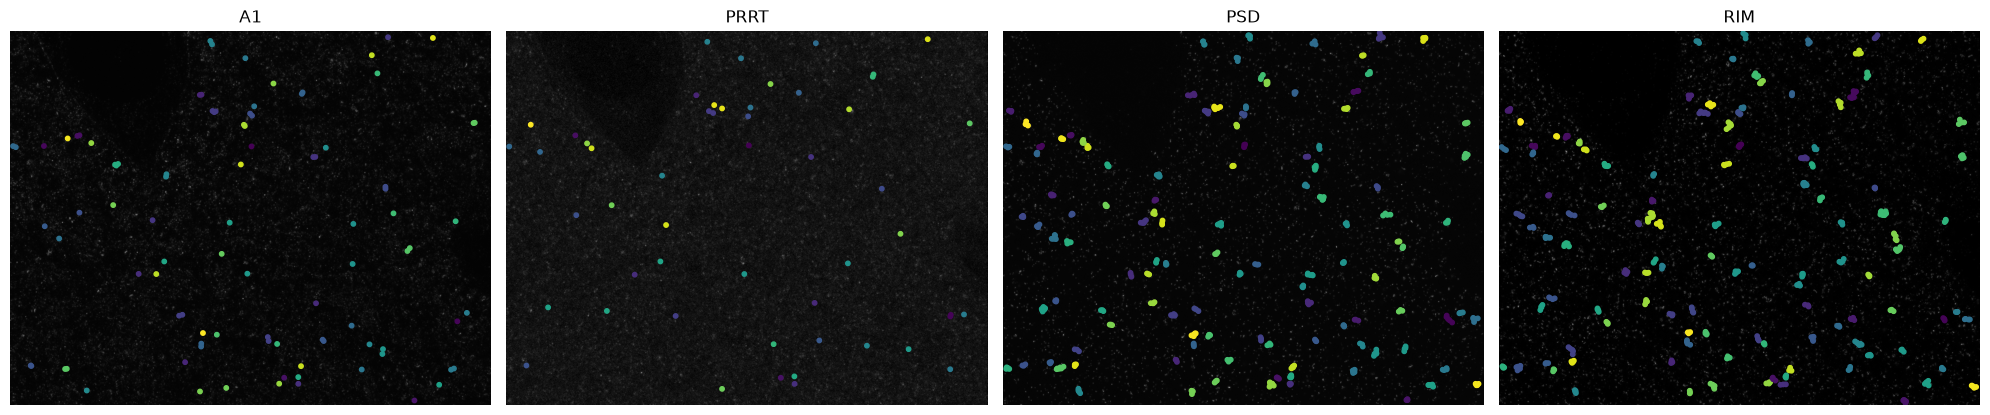

In [35]:
points = synxm.associate_to_paired_cluster(points,**parameters["association"])
points = synxm.compute_distances(points)

fig = plt.figure(figsize=(20, 20))
fig, axes = synxm.plot_data(tmp, split=True, fig=fig)
for n, g in points.groupby("C"):
    g=g[g["synapse_id"]>=0]
    axes[n].scatter(g["X"], g["Y"], c=g["synapse_id"], s=10)


Extract statistics

In [36]:
gst = synxm.global_stats(points, 1, 2., 1)
sst = synxm.synapse_stats(points)

In [38]:
gst

{'Volume window': 106214.0,
 'Number of PRRT puncta': 512,
 'Number of A1 puncta': 1135,
 'Number of PSD puncta': 4625,
 'Number of RIM puncta': 5261,
 'Number of PSD cluster': 311,
 'Number of RIM cluster': 459,
 'Number of synpases': 112,
 'Number of GluA1 synpases': 70,
 'Number of PRRT+GluA1 synpases': 21,
 'Number of PRRT+GluA1 total': 212,
 'Average distance of A1 to RIM': 0.7236249682521602,
 'Average distance of A1 to PSD': 0.36955732926865825,
 'Average distance of PRRT to RIM': 0.812346319107881,
 'Average distance of PRRT to PSD': 0.4566319146664587,
 'poisson pvalue PRRT:A1': 0.0,
 'poisson pvalue PRRT:PSD': 0.0,
 'poisson pvalue PRRT:RIM': 0.0,
 'poisson pvalue A1:PRRT': 0.0,
 'poisson pvalue A1:PSD': 0.0,
 'poisson pvalue A1:RIM': 0.0,
 'poisson pvalue PSD:PRRT': 0.0,
 'poisson pvalue PSD:A1': 0.0,
 'poisson pvalue PSD:RIM': 0.0,
 'poisson pvalue RIM:PRRT': 0.0,
 'poisson pvalue RIM:A1': 0.0,
 'poisson pvalue RIM:PSD': 0.0,
 'monte carlo pvalue PRRT:A1': 0.000999000999000

Make figure

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


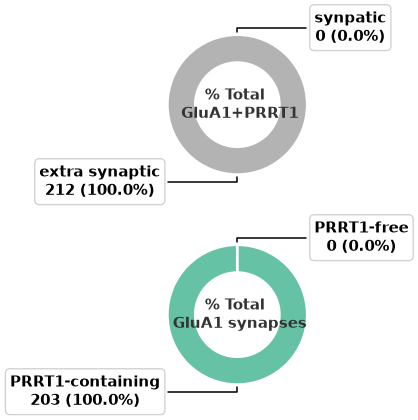

In [15]:
from synxm.plot import make_the_bagel_plot

make_the_bagel_plot(gst,sst)

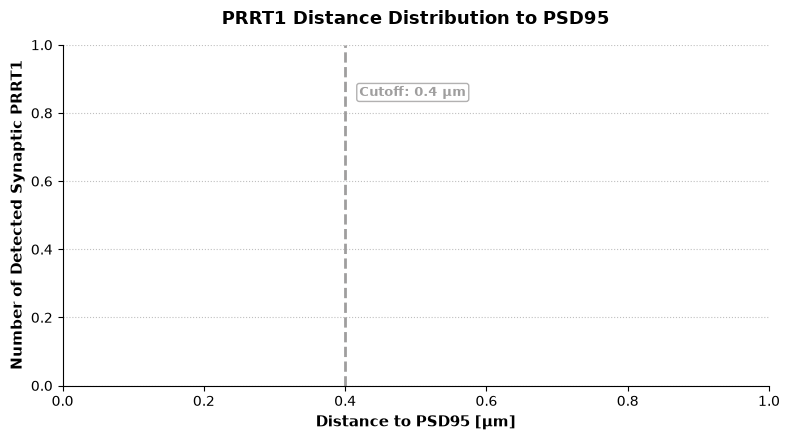

Series([], Name: distance to PSD, dtype: float64)

In [16]:
from synxm.plot import make_the_histogram_distance

make_the_histogram_distance(points)